In [1]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
print("ok")

Matplotlib is building the font cache; this may take a moment.


ok


In [2]:
img_dir = "../data/Val/Urban/images_png"
mask_dir = "../data/Val/Urban/masks_png"

In [3]:
files = sorted(f for f in os.listdir(img_dir) if f.endswith(".png") )
print (len(files))
print(files[:3])

677
['3514.png', '3515.png', '3516.png']


In [4]:
from PIL import Image
name = files[0]
img = Image.open(os.path.join(img_dir , name))
mask = Image.open(os.path.join(mask_dir , name))
print(img.size, img.mode)
print(mask.size, mask.mode)

(1024, 1024) RGB
(1024, 1024) L


In [5]:
arr = np.array(mask)
print(arr.shape, arr.dtype)
values, counts = np.unique(arr, return_counts=True)
print (values)
print (counts)


(1024, 1024) uint8
[1 3 4 7]
[ 19074  49500 109563 870439]


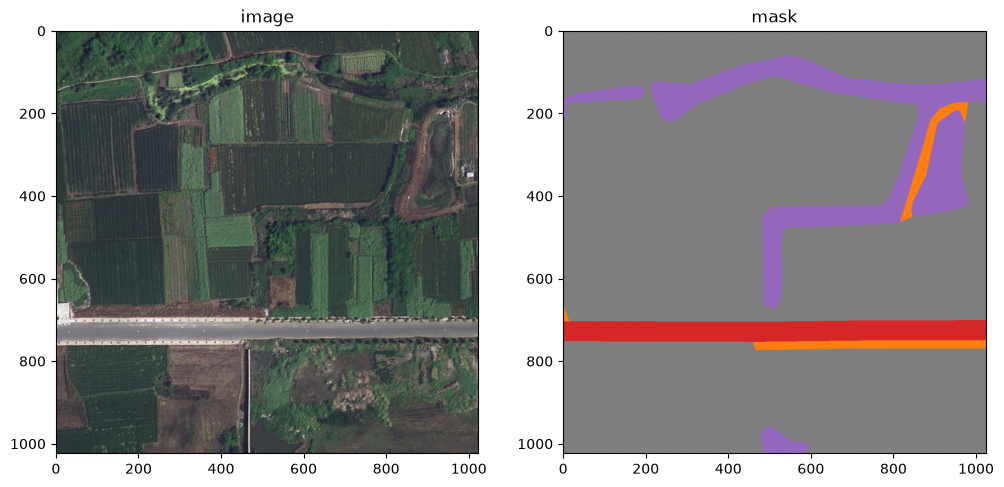

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12,16))
ax[0].imshow(img)
ax[0].set_title("image")
ax[1].imshow(arr, cmap="tab10", vmin=0, vmax=9)
ax[1].set_title("mask")
plt.show()

In [8]:
for name in files[:10]:
    m = np.array(Image.open(os.path.join(mask_dir,name)))
    print(name, np.unique(m))

3514.png [1 3 4 7]
3515.png [1 2 3 4 6 7]
3516.png [1 2 3 4 5 6 7]
3517.png [1 2 3 4 5 6 7]
3518.png [0 1 2 3 5 6]
3519.png [4]
3520.png [0 1 2 3 4 5 6 7]
3521.png [1 3 4 5 6 7]
3522.png [1 2 3 4 5 6 7]
3523.png [1 2 3 4 5 6 7]


In [9]:
total = np.zeros(8, dtype=np.int64)
for name in files[:10]:
    m = np.array(Image.open(os.path.join(mask_dir, name)))
    total += np.bincount(m.ravel(), minlength=8)
print(total / total.sum())

[0.06421776 0.20128517 0.08374052 0.05577564 0.22210093 0.0397459
 0.10251913 0.23061495]
